### **Student Information**
GitHub ID:Levi-droidd

Kaggle name:Ge Zheng Pee

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

* Joined the three provided files on `post_id`: `final_posts.json` (text), `data_identification.csv` (train/test split) and `emotion.csv` (labels). This gives 3,360 training posts and 1,440 test posts.
* The six emotions are imbalanced: joy is the largest class (875 posts) and fear the smallest (288).
* Light cleaning only: anonymised `[NAME]` placeholders are replaced by a single token `name_token`, and repeated spaces and line breaks are collapsed.
* Punctuation, emoji and stop words are kept on purpose: the posts are short (median 13 words), and tokens such as "!", 😢 or "not" carry emotion.

### 1.2 Feature Engineering Steps

Four feature sets, placed side by side in one matrix:

1. **Word TF-IDF**: unigrams + bigrams, with `sublinear_tf`.
2. **Character TF-IDF** (`char_wb`, 2-5 characters): robust to typos, slang and emoji.
3. **MiniLM sentence embeddings** (`all-MiniLM-L6-v2`, 384 dimensions): capture the meaning of the sentence.
4. **Emotion-model embeddings** (`j-hartmann/emotion-english-distilroberta-base`, mean of the last hidden layer, 768 dimensions): a model already trained on emotion data. Added in v2.

### 1.3 Explanation of Your Model

* Classifier: **LinearSVC** (`C=0.3`, `class_weight="balanced"` so the smaller emotions are not ignored).
* Feature sets were compared with 5-fold stratified cross-validation (macro F1):

| Features | CV macro F1 |
|---|---|
| Word + character TF-IDF | 0.516 |
| + MiniLM (v1) | 0.554 |
| + emotion-model probabilities | 0.604 |
| **+ emotion-model embeddings (v2, final)** | **0.610** |
| + both probabilities and embeddings | 0.609 |

* **Error analysis** (5-fold out-of-fold predictions on the training set, row percentages):

![Confusion matrix of the final model](./pics/v2_confusion.png)

  * **Disgust is the hardest emotion** (F1 0.463, recall 43%): 26% of disgust posts are predicted as anger, the largest off-diagonal cell. Both are hostile, negative emotions with similar wording.
  * **Joy is the easiest** (F1 0.749), the largest class with distinctive vocabulary.
  * Class size is not the only factor: fear is the smallest class (288 posts) yet reaches F1 0.620, so disgust suffers from its overlap with anger rather than from a lack of data. Surprise is also often predicted as joy (15%), probably because many surprises are pleasant.
* **Tried but not used:** fine-tuning the emotion model directly. On a 15% holdout its best score was 0.631 (epoch 2), below v2's 0.637 on the same holdout, and it started to overfit from epoch 3. Each epoch took about 6 minutes on CPU, so I kept v2.
* **Kaggle results:** v1 public 0.5575, v2 public 0.5850; final **private 0.6075, rank 80**. The private score is almost the same as the CV estimate (0.610), so cross-validation was a reliable guide.
* **Limitations and next steps:** everything ran on CPU. With more time, I would fine-tune a larger model (e.g. RoBERTa) on a GPU.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I used Claude as an assistant for some questions:

1. *"How can I beat the 0.5 baseline with the methods from the Master notebook?"* The AI found that plain TF-IDF alone scored below 0.5 and suggested adding character n-grams and MiniLM embeddings. **Adopted**: CV rose to 0.554.
2. My first submission failed. The AI read Kaggle's error message and found the ID column must be named `id`, not `post_id` as in the sample file. **Adopted.**
3. *"Should I fine-tune the model?"* Tried and **rejected**, for the reasons in 1.3.


---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
### Add the code related to the preprocessing steps in cells inside this section
import json, re
import numpy as np
import pandas as pd

DATA = "data/kaggle/"
# Three source files, joined on post_id
posts = pd.DataFrame(json.load(open(DATA + "final_posts.json", encoding="utf-8")))
split = pd.read_csv(DATA + "data_identification.csv")   # post_id -> train / test
labels = pd.read_csv(DATA + "emotion.csv")              # post_id -> emotion (train only)
df = posts.merge(split, on="post_id").merge(labels, on="post_id", how="left")

def clean(text):
    # Anonymised names appear as [NAME]; turn them into one ordinary token
    text = text.replace("[NAME]", " name_token ")
    # Collapse newlines and repeated spaces; keep punctuation and emoji (they carry emotion)
    return re.sub(r"\s+", " ", text).strip()

df["clean"] = df["text"].map(clean)
train = df[df["set"] == "train"].reset_index(drop=True)
test = df[df["set"] == "test"].reset_index(drop=True)
print("train:", train.shape, "| test:", test.shape)
print(train["label"].value_counts())

train: (3360, 5) | test: (1440, 5)
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


## 2. Feature Engineering Steps

In [2]:
### Add the code related to the feature engineering steps in cells inside this section
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

# 1. Word TF-IDF, unigrams + bigrams; sublinear_tf damps words repeated in one post
word_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
# 2. Character TF-IDF (2-5 letters inside words): robust to typos, slang and emoji
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2)
X_train_tfidf = hstack([word_vec.fit_transform(train["clean"]),
                        char_vec.fit_transform(train["clean"])]).tocsr()
X_test_tfidf = hstack([word_vec.transform(test["clean"]),
                       char_vec.transform(test["clean"])]).tocsr()

# 3. MiniLM sentence embeddings (pre-trained meaning, 384 numbers per post),
#    the same model as the Master notebook, already cached on this computer
st = SentenceTransformer("all-MiniLM-L6-v2")
E_train = st.encode(train["clean"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=True)
E_test = st.encode(test["clean"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=True)

# Combined version: TF-IDF columns and embedding columns side by side
X_train_both = hstack([X_train_tfidf, csr_matrix(E_train)]).tocsr()
X_test_both = hstack([X_test_tfidf, csr_matrix(E_test)]).tocsr()
print("TF-IDF only:", X_train_tfidf.shape, "| TF-IDF + MiniLM:", X_train_both.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/53 [00:00<?, ?it/s]

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

TF-IDF only: (3360, 64645) | TF-IDF + MiniLM: (3360, 65029)


## 3. Model Implementation Steps

In [3]:
### Add the code related to the model implementation steps in cells inside this section
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

y = train["label"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # same 5 splits for both
candidates = {"TF-IDF word+char": (X_train_tfidf, X_test_tfidf),
              "TF-IDF + MiniLM": (X_train_both, X_test_both)}

# 5-fold macro F1 on the training set estimates the leaderboard score
scores = {}
for name, (Xtr, _) in candidates.items():
    model = LinearSVC(C=0.3, class_weight="balanced")   # balanced: rare emotions count more
    scores[name] = cross_val_score(model, Xtr, y, cv=cv, scoring="f1_macro").mean()
    print(f"{name}: 5-fold macro F1 = {scores[name]:.3f}")

# Refit the better version on all training posts and predict the test posts
best = max(scores, key=scores.get)
Xtr, Xte = candidates[best]
final = LinearSVC(C=0.3, class_weight="balanced").fit(Xtr, y)
# Kaggle expects the header "id,label" (its sample file says post_id, but the grader wants id)
sub = pd.DataFrame({"id": test["post_id"], "label": final.predict(Xte)})
sub.to_csv("submission.csv", index=False)
print("chosen:", best, "| wrote submission.csv with", len(sub), "rows")
print(sub["label"].value_counts())

TF-IDF word+char: 5-fold macro F1 = 0.516
TF-IDF + MiniLM: 5-fold macro F1 = 0.554
chosen: TF-IDF + MiniLM | wrote submission.csv with 1440 rows
label
joy         406
anger       314
sadness     250
surprise    179
disgust     172
fear        119
Name: count, dtype: int64


In [4]:
# --- Improvement: features from a pre-trained emotion classifier ---
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.model_selection import cross_val_score

# DistilRoBERTa fine-tuned on English emotion data (7 classes incl. neutral)
EMO_MODEL = "j-hartmann/emotion-english-distilroberta-base"
tok = AutoTokenizer.from_pretrained(EMO_MODEL)
emo = AutoModelForSequenceClassification.from_pretrained(EMO_MODEL).eval()
print("emotion model labels:", emo.config.id2label)

def emo_features(texts, batch_size=32):
    '''Return (class probabilities, mean-pooled last hidden layer) for each text.'''
    probs, embs = [], []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = tok(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=128, return_tensors="pt")
            out = emo(**batch, output_hidden_states=True)
            probs.append(torch.softmax(out.logits, dim=-1).numpy())
            h, mask = out.hidden_states[-1], batch["attention_mask"].unsqueeze(-1)
            embs.append(((h * mask).sum(1) / mask.sum(1)).numpy())   # average over real tokens
    P, H = np.vstack(probs), np.vstack(embs)
    return P, H / np.linalg.norm(H, axis=1, keepdims=True)           # unit-length like MiniLM

P_train, H_train = emo_features(train["clean"].tolist())
P_test, H_test = emo_features(test["clean"].tolist())
print("probabilities:", P_train.shape, "| hidden vectors:", H_train.shape)

# Four feature sets, all compared with the same model and the same 5 folds
def add(base, extra):
    return hstack([base, csr_matrix(extra)]).tocsr()

candidates2 = {
    "TF-IDF + MiniLM (v1)":       (X_train_both, X_test_both),
    "+ emotion probabilities":    (add(X_train_both, 2 * P_train), add(X_test_both, 2 * P_test)),
    "+ emotion hidden vector":    (add(X_train_both, H_train), add(X_test_both, H_test)),
    "+ both":                     (add(add(X_train_both, 2 * P_train), H_train),
                                   add(add(X_test_both, 2 * P_test), H_test)),
}
scores2 = {}
for name, (Xtr, _) in candidates2.items():
    model = LinearSVC(C=0.3, class_weight="balanced")
    scores2[name] = cross_val_score(model, Xtr, y, cv=cv, scoring="f1_macro").mean()
    print(f"{name}: 5-fold macro F1 = {scores2[name]:.3f}")

# Refit the best on all training posts; save as a separate file so v1 stays intact
best2 = max(scores2, key=scores2.get)
Xtr, Xte = candidates2[best2]
final2 = LinearSVC(C=0.3, class_weight="balanced").fit(Xtr, y)
sub2 = pd.DataFrame({"id": test["post_id"], "label": final2.predict(Xte)})
sub2.to_csv("submission_v2.csv", index=False)
print("chosen:", best2, "| wrote submission_v2.csv with", len(sub2), "rows")
print(sub2["label"].value_counts())

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

emotion model labels: {0: 'anger', 1: 'disgust', 2: 'fear', 3: 'joy', 4: 'neutral', 5: 'sadness', 6: 'surprise'}
probabilities: (3360, 7) | hidden vectors: (3360, 768)
TF-IDF + MiniLM (v1): 5-fold macro F1 = 0.554
+ emotion probabilities: 5-fold macro F1 = 0.604
+ emotion hidden vector: 5-fold macro F1 = 0.610
+ both: 5-fold macro F1 = 0.609
chosen: + emotion hidden vector | wrote submission_v2.csv with 1440 rows
label
joy         360
anger       329
sadness     263
surprise    201
disgust     166
fear        121
Name: count, dtype: int64


              precision    recall  f1-score   support

       anger      0.569     0.622     0.594       674
     disgust      0.500     0.432     0.463       454
        fear      0.622     0.618     0.620       288
         joy      0.745     0.752     0.749       875
     sadness      0.636     0.629     0.633       628
    surprise      0.601     0.601     0.601       441

    accuracy                          0.628      3360
   macro avg      0.612     0.609     0.610      3360
weighted avg      0.627     0.628     0.627      3360



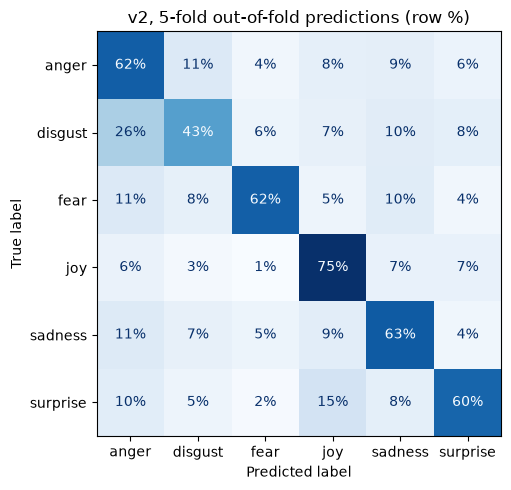

In [5]:
# --- Error analysis for the final model (v2): cross-validated confusion matrix ---
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Out-of-fold predictions: every training post is predicted by a model that never saw it
Xv2_train, _ = candidates2[best2]
y_oof = cross_val_predict(LinearSVC(C=0.3, class_weight="balanced"), Xv2_train, y, cv=cv)

# Per-emotion precision / recall / F1, to see which emotions are hardest
print(classification_report(y, y_oof, digits=3))

# Confusion matrix as row percentages: each row shows where one true emotion went
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y, y_oof, normalize="true", values_format=".0%",
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title("v2, 5-fold out-of-fold predictions (row %)")
plt.tight_layout()
plt.savefig("pics/v2_confusion.png", dpi=120)   # saved so the report can show it
plt.show()

In [6]:
# --- v3: fine-tune the emotion model itself on the competition labels ---
import os, time, random
import torch
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from transformers import get_linear_schedule_with_warmup

torch.manual_seed(42); random.seed(42); np.random.seed(42)
torch.set_num_threads(os.cpu_count())          # use every CPU core

LABELS6 = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
name2pos = {v: k for k, v in emo.config.id2label.items()}
POS6 = [name2pos[l] for l in LABELS6]          # keep the pretrained head; skip "neutral"

# Class weights (inverse square root of frequency) so rare emotions are not ignored
freq = y.value_counts()
w = torch.ones(len(name2pos))
for l in LABELS6:
    w[name2pos[l]] = float((freq.max() / freq[l]) ** 0.5)

def predict_proba6(model, texts, bs=64):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            batch = tok(texts[i:i + bs], padding=True, truncation=True, max_length=64, return_tensors="pt")
            out.append(torch.softmax(model(**batch).logits[:, POS6], dim=-1).numpy())
    return np.vstack(out)

def predict6(model, texts):
    return [LABELS6[j] for j in predict_proba6(model, texts).argmax(1)]

def fine_tune(texts, labels, epochs, eval_texts=None, eval_labels=None, bs=16):
    '''Fine-tune a fresh copy of the emotion model; report holdout macro F1 per epoch.'''
    model = AutoModelForSequenceClassification.from_pretrained(EMO_MODEL)
    targets = torch.tensor([name2pos[l] for l in labels])
    opt = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    steps = epochs * ((len(texts) + bs - 1) // bs)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    loss_fn = torch.nn.CrossEntropyLoss(weight=w)
    history = []
    for ep in range(epochs):
        model.train(); t0 = time.time()
        order = np.random.permutation(len(texts))
        for b in range(0, len(order), bs):
            idx = order[b:b + bs]
            batch = tok([texts[i] for i in idx], padding=True, truncation=True, max_length=64, return_tensors="pt")
            loss = loss_fn(model(**batch).logits, targets[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
        msg = f"epoch {ep + 1}/{epochs}: {time.time() - t0:.0f}s"
        if eval_texts is not None:
            f1 = f1_score(eval_labels, predict6(model, eval_texts), average="macro")
            history.append(f1); msg += f" | holdout macro F1 = {f1:.3f}"
        print(msg, flush=True)
    return model, history

# Hold out 15% of the training posts (stratified) as a fair test for both methods
texts_all = train["clean"].tolist()
idx_tr, idx_ho = train_test_split(np.arange(len(train)), test_size=0.15, stratify=y, random_state=42)

# v2 on exactly the same split, for a like-for-like comparison
Xv2_train, Xv2_test = candidates2[best2]
svm_ho = LinearSVC(C=0.3, class_weight="balanced").fit(Xv2_train[idx_tr], y.iloc[idx_tr])
v2_ho = f1_score(y.iloc[idx_ho], svm_ho.predict(Xv2_train[idx_ho]), average="macro")
print(f"v2 ({best2}) on the holdout: macro F1 = {v2_ho:.3f}")

_, ft_history = fine_tune([texts_all[i] for i in idx_tr], y.iloc[idx_tr].tolist(), epochs=4,
                          eval_texts=[texts_all[i] for i in idx_ho], eval_labels=y.iloc[idx_ho].tolist())
best_epochs = int(np.argmax(ft_history)) + 1
print(f"\nfine-tuned best: {max(ft_history):.3f} after {best_epochs} epoch(s) | v2: {v2_ho:.3f}")
print("fine-tuning wins -> run the next cell" if max(ft_history) > v2_ho + 0.01
      else "no clear win -> keep v2 (submission_v2.csv)")

v2 (+ emotion hidden vector) on the holdout: macro F1 = 0.637


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

epoch 1/4: 352s | holdout macro F1 = 0.610
epoch 2/4: 377s | holdout macro F1 = 0.631
epoch 3/4: 346s | holdout macro F1 = 0.621
epoch 4/4: 343s | holdout macro F1 = 0.617

fine-tuned best: 0.631 after 2 epoch(s) | v2: 0.637
no clear win -> keep v2 (submission_v2.csv)
